<a href="https://colab.research.google.com/github/imagra93/ML-course-labs/blob/main/notebooks/neural_networks/lab 14 - Text generation with Transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab · Text generation with transformers (GPT-2)

A **language model** gives a probability to every possible next token given the text so far. Generating text is then a loop: predict a distribution, pick a token, append it, repeat. In this lab you use **GPT-2** (OpenAI, 2019) through the Hugging Face `transformers` library, the standard way to load and run pre-trained models. You will see how text becomes tokens, what the model outputs, how the **decoding** settings turn the same model into a boring or a creative writer, how to score text with **perplexity**, and how to steer a model with a prompt.

**Contents**

1. Setup
2. The tokenizer: text to tokens
3. The model: one forward pass
4. Generating text with `model.generate`
5. Scoring text: perplexity
6. A base model is not an assistant: prompting
7. Summary and practical tips

Theory: Part B of the slides [Attention and transformers](https://imagra93.github.io/ML-course-labs/slides/neural_networks/06_transformers.html) (GPT, tokens, decoding, perplexity). Byte-pair encoding from scratch, the parameter count, the attention maps, the KV cache and sampling written by hand are in the **extended version** of this lab, linked at the end.

Everything runs on a CPU in a few minutes; a GPU makes generation faster.

## 1. Setup

Colab already includes `transformers`; the first cell installs it elsewhere if it is missing. GPT-2 small (500 MB) is downloaded from the Hugging Face Hub the first time.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("transformers") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers"], check=True)

import math
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 2. The tokenizer: text to tokens

A model works with a fixed vocabulary of **tokens**. GPT-2 uses **byte-pair encoding** (BPE): starting from single characters, the most frequent pairs of symbols in its training text were merged again and again, 50,000 times. Frequent words became single tokens; rare words are split into frequent pieces.

`AutoTokenizer.from_pretrained(name)` loads the tokenizer that belongs to a model. `encode` turns text into token ids, `decode` turns ids back into text. A token that starts with a space is shown with `Ġ`: the space is part of the token.

In [2]:
tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
print("vocabulary size:", tokenizer.vocab_size, "  end-of-text token:", tokenizer.eos_token, tokenizer.eos_token_id)

ids = tokenizer.encode("Welcome to the deep learning class")
print("\nids:   ", ids)
print("tokens:", tokenizer.convert_ids_to_tokens(ids))
print("decode:", repr(tokenizer.decode(ids)))

print()
for text in ["Bienvenidos a la clase de aprendizaje profundo", "unbelievably", "In 2024 there were 8784 hours."]:
    ids = tokenizer.encode(text)
    print(f"{len(text.split()):>2} words -> {len(ids):>2} tokens | {tokenizer.convert_ids_to_tokens(ids)}")

vocabulary size: 50257   end-of-text token: <|endoftext|> 50256

ids:    [14618, 284, 262, 2769, 4673, 1398]
tokens: ['Welcome', 'Ġto', 'Ġthe', 'Ġdeep', 'Ġlearning', 'Ġclass']
decode: 'Welcome to the deep learning class'

 7 words -> 17 tokens | ['B', 'ien', 'ven', 'id', 'os', 'Ġa', 'Ġla', 'Ġcl', 'ase', 'Ġde', 'Ġap', 'rend', 'iz', 'aj', 'e', 'Ġprof', 'undo']
 1 words ->  4 tokens | ['un', 'bel', 'iev', 'ably']
 6 words ->  8 tokens | ['In', 'Ġ2024', 'Ġthere', 'Ġwere', 'Ġ8', '784', 'Ġhours', '.']


- Common English words are one token each. The Spanish sentence needs far more tokens per word: GPT-2's merges were learned on English text. A model is more expensive (APIs charge per token) and usually worse in languages its tokenizer under-represents.
- Numbers are cut into irregular chunks, one reason why language models are bad at arithmetic.

## 3. The model: one forward pass

`AutoModelForCausalLM.from_pretrained(name)` loads the transformer together with its **language-modelling head**, which maps each position to $V = 50{,}257$ logits, one per token. GPT-2 small has 12 transformer blocks and 124 million parameters.

For an input of $T$ tokens the model returns logits of shape $(1, T, V)$: at **every** position it predicts the next token. Training scores all $T$ predictions at once with the cross-entropy loss; generation only needs the last one.

In [3]:
model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device)
model.eval()
print(f"{sum(p.numel() for p in model.parameters()):,} parameters, {model.config.n_layer} blocks, "
      f"context of {model.config.n_positions} tokens")

text = "Welcome to the deep learning class, it is a"
ids = tokenizer.encode(text, return_tensors="pt").to(device)
with torch.no_grad():
    logits = model(ids).logits
print("input ids:", tuple(ids.shape), "-> logits:", tuple(logits.shape), "(batch, positions, vocabulary)")

for t in range(ids.shape[1]):
    best = logits[0, t].argmax().item()
    print(f"after {tokenizer.decode(ids[0, :t + 1])!r:<48} -> most likely next token {tokenizer.decode(best)!r}")

124,439,808 parameters, 12 blocks, context of 1024 tokens


input ids: (1, 10) -> logits: (1, 10, 50257) (batch, positions, vocabulary)
after 'Welcome'                                        -> most likely next token ' to'
after 'Welcome to'                                     -> most likely next token ' the'
after 'Welcome to the'                                 -> most likely next token ' latest'
after 'Welcome to the deep'                            -> most likely next token ' web'
after 'Welcome to the deep learning'                   -> most likely next token ' community'
after 'Welcome to the deep learning class'             -> most likely next token '.'
after 'Welcome to the deep learning class,'            -> most likely next token ' where'
after 'Welcome to the deep learning class, it'         -> most likely next token "'s"
after 'Welcome to the deep learning class, it is'      -> most likely next token ' a'
after 'Welcome to the deep learning class, it is a'    -> most likely next token ' great'


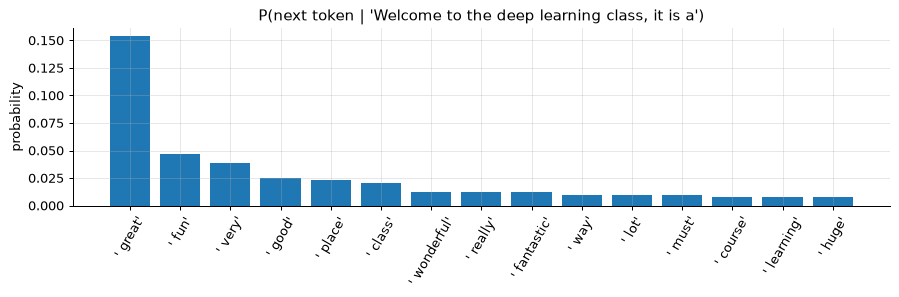

the 15 most likely tokens hold only 40% of the probability


In [4]:
probs = torch.softmax(logits[0, -1], dim=-1)          # the distribution of the next token
top = torch.topk(probs, 15)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar([repr(tokenizer.decode(i)) for i in top.indices.tolist()], top.values.cpu().numpy())
ax.set_ylabel("probability"); ax.tick_params(axis="x", rotation=60)
ax.set_title(f"P(next token | {text!r})")
plt.tight_layout(); plt.show()
print(f"the 15 most likely tokens hold only {top.values.sum():.0%} of the probability")

The distribution is spread out: many continuations are plausible. How we choose among them is the **decoding** problem.

## 4. Generating text with `model.generate`

`model.generate` runs the loop "predict, choose a token, append it" for us. The choice of token is controlled by a few arguments:

| Strategy | Arguments | What it does |
|---|---|---|
| **greedy** | `do_sample=False` | always take the most likely token |
| **beam search** | `do_sample=False, num_beams=5` | keep the 5 most likely partial sentences at each step, return the best complete one |
| **sampling** | `do_sample=True, temperature=τ` | draw the next token at random from the distribution, after dividing the logits by $\tau$: $\tau < 1$ sharpens it, $\tau > 1$ flattens it |
| **top-k** | `top_k=40` | sample only among the 40 most likely tokens |
| **top-p** (nucleus) | `top_p=0.9` | sample only among the most likely tokens that together reach 90% of the probability |

Other useful arguments: `max_new_tokens` (how many tokens to add), `no_repeat_ngram_size=3` (never repeat a 3-token sequence), and `pad_token_id=tokenizer.eos_token_id` (GPT-2 has no padding token; this silences a warning).

In [5]:
def generate(prompt, seed=0, max_new_tokens=40, **kwargs):
    torch.manual_seed(seed)                                     # sampling is random: fix the seed to reproduce it
    enc = tokenizer(prompt, return_tensors="pt").to(device)
    out = model.generate(**enc, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.eos_token_id, **kwargs)
    return tokenizer.decode(out[0], skip_special_tokens=True).replace("\n", " ")

prompt = "The key to training neural networks is"
settings = {
    "greedy":                          dict(do_sample=False),
    "beam search, 5 beams":            dict(do_sample=False, num_beams=5),
    "beam search + no_repeat_ngram":   dict(do_sample=False, num_beams=5, no_repeat_ngram_size=3),
    "sampling, temperature 1.8":       dict(do_sample=True, temperature=1.8, top_k=0),
    "sampling, temperature 0.8, top-k 40": dict(do_sample=True, temperature=0.8, top_k=40),
    "sampling, temperature 0.9, top-p 0.9": dict(do_sample=True, temperature=0.9, top_p=0.9, top_k=0),
}
for name, kw in settings.items():
    print(f"=== {name}\n{generate(prompt, **kw)}\n")

=== greedy
The key to training neural networks is to train them to recognize the world around them.  "We're not going to be able to do that with the human brain," says Dr. Michael J. Schoenfeld, a neuro



=== beam search, 5 beams
The key to training neural networks is to train them in a way that allows them to learn from each other.  In this article, I'll show you how to train neural networks to learn from each other. I'll also show



=== beam search + no_repeat_ngram
The key to training neural networks is to train them in a way that allows them to learn from each other.  In this post, I'll show you how to train a neural network to learn a new word. I'll also



=== sampling, temperature 1.8
The key to training neural networks is bell pressure. Compolla calculates results similary torentice neuroscience acetoglobin reliable from television Jennings togethericipsiecer garbage rotating baseball sackcos mar x angel bat wowaffle Bill Sox resulted win/loss records



=== sampling, temperature 0.8, top-k 40
The key to training neural networks is to recognize and adapt their inputs.  We can use neural networks to learn to recognize input patterns and to identify which patterns will be used during training. For example, when training an input, we



=== sampling, temperature 0.9, top-p 0.9
The key to training neural networks is to recognize and adapt their inputs.  We can use neural networks to improve our performance, making them more efficient at learning.  We've already shown that working memory training works.  



- **Greedy** and **beam search** produce fluent but bland text, and beam search already repeats itself ("I'll show you how to train neural networks to learn from each other. I'll also show..."). In longer outputs greedy decoding falls into loops: once a phrase has been generated, repeating it becomes the most likely continuation. `no_repeat_ngram_size=3` forbids exact repeats.
- **Pure sampling at a high temperature** (1.8, no top-k) gives real probability to the long tail of 50,000 unlikely tokens, and the text derails into nonsense within a few words.
- **Top-k and top-p** cut that tail and keep the variety: the text is fluent and less predictable. A temperature of 0.7 to 1 with top-p 0.9 is a common default for creative text.

Sampling gives a different text for every seed:

In [6]:
for seed in range(3):
    print(f"[seed {seed}]", generate("Studying the MINT master is the best decision I", seed=seed, max_new_tokens=30,
                                     do_sample=True, temperature=0.9, top_p=0.9, top_k=0), "\n")

[seed 0] Studying the MINT master is the best decision I ever made. I think that is the point of building software.  Software is the single most important thing you can learn. It is like a 



[seed 1] Studying the MINT master is the best decision I've made to date. You should start with the one that comes closest to you. Because sometimes an Amazon or B&H expert will ask you a 



[seed 2] Studying the MINT master is the best decision I've ever made. The great thing about mastering is the opportunity to get to know your palate and learn the difference between simple and complex flavors and styles. 



## 5. Scoring text: perplexity

The same model that generates text can **score** it. If we pass `labels=ids`, the model returns the training loss: the mean negative log-probability of each token given the previous ones. Its exponential is the **perplexity**:

$$
\text{PPL} = \exp\Big(-\frac{1}{T}\sum_{t}\log p(w_t \mid w_{<t})\Big) .
$$

A perplexity of 20 means the model is, on average, as uncertain as if it had to choose uniformly among 20 tokens at each step. Lower means more likely, more "natural" text for the model.

In [7]:
def perplexity(text):
    ids = tokenizer.encode(text, return_tensors="pt").to(device)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss                       # mean cross-entropy of the next-token predictions
    return math.exp(loss.item())

sentences = {
    "natural English":      "The cat sat on the mat and looked out of the window.",
    "same words, shuffled": "Window the mat of cat the out on and sat looked the.",
    "Spanish":              "El gato se sentó en la alfombra y miró por la ventana.",
    "true fact":            "Paris is the capital of France.",
    "false fact":           "Paris is the capital of Germany.",
}
for name, s in sentences.items():
    print(f"{name:<22} perplexity {perplexity(s):>8.1f}   {s}")

natural English        perplexity     21.7   The cat sat on the mat and looked out of the window.
same words, shuffled   perplexity   1535.4   Window the mat of cat the out on and sat looked the.
Spanish                perplexity    235.4   El gato se sentó en la alfombra y miró por la ventana.
true fact              perplexity     15.8   Paris is the capital of France.
false fact             perplexity     17.8   Paris is the capital of Germany.


- Shuffling the same words multiplies the perplexity by about 70: the model has learned grammar and word order, not only which words are frequent.
- Spanish is about 10 times less likely than English: GPT-2 saw little Spanish.
- The false fact is only slightly less likely than the true one (17.8 against 15.8). The model has absorbed some world knowledge as statistics about which words go together, but perplexity measures how **likely** a text is, not whether it is **true**. Language models will happily generate false statements.

## 6. A base model is not an assistant: prompting

GPT-2 is a **base model**: it only continues text in the style of the web pages it was trained on. It has no notion of "answering" a question and then stopping. But we can **show** it the format we want: with a few examples in the prompt, the pattern becomes the most likely continuation. This is **few-shot prompting** (in-context learning): no weight changes, the task is given by the prompt.

In [8]:
def complete(prompt, n=15):
    enc = tokenizer(prompt, return_tensors="pt").to(device)
    out = model.generate(**enc, max_new_tokens=n, do_sample=False, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0, enc["input_ids"].shape[1]:])     # only the new tokens

print("zero-shot:", repr(complete("What is the capital of France?")))
few_shot = ("Q: What is the capital of Italy?\nA: Rome\n"
            "Q: What is the capital of Japan?\nA: Tokyo\n"
            "Q: What is the capital of France?\nA:")
print("few-shot: ", repr(complete(few_shot, 4)))
translate = "English: cat\nFrench: chat\nEnglish: dog\nFrench: chien\nEnglish: house\nFrench:"
print("few-shot translation:", repr(complete(translate, 3)))

zero-shot: '\n\nThe capital of France is Paris.\n\nThe capital of France'


few-shot:  ' Paris\nQ:'
few-shot translation: ' house\nFrench'


- **Zero-shot**, GPT-2 produces the right fact and then keeps going, repeating itself: nothing tells it that the answer is complete.
- **Few-shot**, the pattern "Q: ... A: short answer" becomes the most likely continuation. The model answers "Paris" in the requested format and then starts the next "Q:" (an application would stop at the line break).
- The few-shot **translation** fails: GPT-2 small just copies "house". In-context learning is weak in small models and grows dramatically with scale; GPT-3, with 175 billion parameters, made it famous.

Chat assistants add two training stages on top of a base model like this one: **instruction tuning** (fine-tuning on examples of instructions and good answers) and **preference optimisation** (for example RLHF, reinforcement learning from human feedback). The RAG lab uses a small instruction-tuned model.

## 7. Summary and practical tips

- A language model predicts a probability for every possible next token, at every position. It is trained with the next-token cross-entropy on raw text: no labels needed.
- **Tokenizers** split text into subword tokens. The number of tokens decides the cost and the context used, and it depends on the language.
- `AutoTokenizer` + `AutoModelForCausalLM` + `generate` is the standard way to use any causal language model of the Hugging Face Hub: change the model name and the same code works.
- **Decoding** turns distributions into text: greedy and beam search are likely but repetitive; sampling with a temperature and top-p is diverse.
- **Perplexity** = exp(mean next-token loss) scores how natural a text is for the model.

**Tips:**
- **Defaults for open-ended text**: `do_sample=True, temperature=0.7–1.0, top_p=0.9`. For factual answers or code: greedy or a low temperature.
- **Repetition**: use `no_repeat_ngram_size` or `repetition_penalty` with greedy or beam search.
- **Reproducibility**: sampling is random; fix the seed with `torch.manual_seed`.
- **Limits**: `max_new_tokens` bounds the output; the context window (1,024 tokens for GPT-2) bounds prompt + output.
- **Base vs instruct models**: a base model continues text, so give it examples of the format you want. An instruction-tuned model follows instructions, with a chat template (`tokenizer.apply_chat_template`).

## Exercises

Try each one before opening the answer.

1. **Temperature.** What happens to the generated text when $\tau \to 0$? And when $\tau$ is very large? Try $\tau = 0.1$ and $\tau = 3$.
2. **Tokens and cost.** An API charges per token. Use the tokenizer to estimate how much more a Spanish paragraph costs than its English translation with GPT-2's vocabulary.
3. **Perplexity as a detector.** How could you use perplexity to rank several candidate answers, or to flag unusual sentences in a document?

<details>
<summary><b>Answers</b></summary>

**1.** Dividing the logits by $\tau$ before the softmax gives $p_\tau(w) \propto p(w)^{1/\tau}$. As $\tau \to 0$ all the probability goes to the most likely token: sampling becomes greedy decoding, with its loops. As $\tau$ grows the distribution becomes flatter, the 50,000 unlikely tokens get real probability, and the text derails into nonsense (you saw it at $\tau = 1.8$). Top-k and top-p cut that tail.

**2.** Count the tokens of a paragraph and of its translation with `len(tokenizer.encode(text))`. For GPT-2, Spanish typically needs between 1.5 and 2.5 times more tokens than English, so it costs that much more and uses that much more of the context window. Tokenizers trained on many languages reduce the gap.

**3.** Compute the perplexity of each candidate (or of the prompt + candidate) and keep the one with the lowest value: it is the most likely continuation for the model. Sentences with a much higher perplexity than the rest of a document are unusual for the model: errors, text in another language, random strings, or text from a very different source. Perplexity measures how *likely*, not how *true*, a text is: in section 5 the false fact was almost as likely as the true one.

</details>

## Going further: the extended lab

The extended version of this lab uses the same model and opens it up:
- language modelling as a product of next-token probabilities; **byte-pair encoding written from scratch**;
- where GPT-2's 124 million parameters are, with the formula and weight tying;
- per-token surprisal; the **attention maps** and the causal mask;
- greedy decoding and the **KV cache** written by hand;
- temperature, top-k and top-p **implemented from scratch**; beam search and repetition penalties; and six exercises.

<a href="https://colab.research.google.com/github/imagra93/ML-course-labs/blob/main/notebooks/neural_networks/lab 14 - Text generation with Transformers - extended.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> [lab 14 - Text generation with Transformers - extended.ipynb](lab%2014%20-%20Text%20generation%20with%20Transformers%20-%20extended.ipynb)